# Telecom Customer Churn Analysis & Threshold Optimization
End-to-end churn prediction and cost-sensitive business optimization.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
# Load Dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Clean numeric column with empty whitespace strings
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# Drop non-predictive identifier
df.drop(columns=["customerID"], inplace=True)

# Encode binary target variable
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# One-hot encode categorical features
df_encoded = pd.get_dummies(df, drop_first=True)

In [3]:
# Separate features and target
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

# Stratified split to preserve churn distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize numerical continuous columns
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [4]:
# Train Random Forest with balanced weights to handle class imbalance
model = RandomForestClassifier(
    n_estimators=150, max_depth=6, class_weight="balanced", random_state=42
)
model.fit(X_train, y_train)

# Predict churn probabilities on the test set
test_probs = model.predict_proba(X_test)[:, 1]

In [5]:
# Business unit economics parameters
CAC = 500.0
OFFER_COST = 50.0
ACCEPTANCE_RATE = 0.60


def calculate_total_cost(threshold):
    preds = (test_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    return fp * OFFER_COST + fn * CAC + tp * (OFFER_COST + (1.0 - ACCEPTANCE_RATE) * CAC)


# Sweep across probability thresholds
thresholds = np.linspace(0.01, 0.99, 99)
costs = [calculate_total_cost(t) for t in thresholds]
best_t = thresholds[np.argmin(costs)]

print(f"Optimal Probability Threshold: {best_t:.2f}")
print(f"Minimum Expected Cost: ${min(costs):,.2f}")
print(f"Cost at default 0.50 threshold: ${calculate_total_cost(0.50):,.2f}")


Optimal Probability Threshold: 0.43
Minimum Expected Cost: $123,850.00
Cost at default 0.50 threshold: $125,650.00


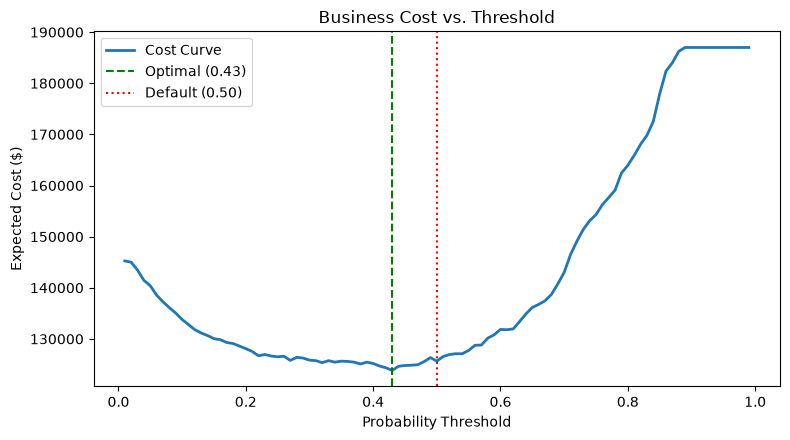

In [6]:
# Plot Cost Curve vs Threshold
plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, costs, color="#1f77b4", lw=2, label="Cost Curve")
plt.axvline(best_t, color="green", linestyle="--", label=f"Optimal ({best_t:.2f})")
plt.axvline(0.50, color="red", linestyle=":", label="Default (0.50)")
plt.title("Business Cost vs. Threshold")
plt.xlabel("Probability Threshold")
plt.ylabel("Expected Cost ($)")
plt.legend()
plt.tight_layout()
plt.show()